# B4 · Mask2Former (Swin) **con clases** (Propuesta 2: modelo integrado)

Afina Mask2Former (Hugging Face, backbone Swin) con las **323 clases**. Es la pareja de A4: **misma arquitectura, mismos datos y mismos hiperparámetros**; solo cambia la tarea.

**Requisitos:** GPU y, en Colab, Google Drive montado. A diferencia de RTMDet-Ins, no depende de MMCV: solo `transformers` (ya viene en Colab).

**Cómo se alimenta (todo desde tu Google Drive):**

| Archivo en Drive | Para qué |
|---|---|
| `food_prep.zip` | Salida del 00: `classes.json`, `splits.json`, `manifest.json`, etc. |
| `Food_Recognition_2022.zip` | Fotos originales (el dataset de Kaggle `food-recognition-2022`, ya guardado en Drive). Se extrae en `/content/data/raw` y se pasa a `Prep` como `raw_dir`. En Colab es **obligatorio**: sin él, `food_utils` bajaría varios GB de Kaggle |
| `food_utils.py` | Utilidades comunes (`Prep`, letterbox, evaluación COCO...) |

Los archivos se **buscan primero en tu carpeta `calorie_counter`** (y sus subcarpetas) y **solo si no están** se intentan bajar con `gdown`. Se extraen en el disco local de Colab (`/content/data`); los **pesos, el historial y los resultados** se guardan en Drive.

**Qué hace**
1. Localiza los archivos (carpeta de Drive y, si faltan, descarga), carga los datos (`food_utils.Prep`) y excluye las fotos con geometría irreconciliable.
2. Carga `facebook/mask2former-swin-*-coco-instance` (pesos COCO) y reinicia la cabeza de clases (`ignore_mismatched_sizes`).
3. Entrena con **mi propio bucle** (letterbox a `imgsz` = **224**, volteo, AdamW con LR del backbone ×0.1, calentamiento + coseno). La pérdida (emparejamiento húngaro + máscaras) la calcula el propio modelo al recibir `mask_labels`/`class_labels`. Cada época evalúa la **validación** (AP con clases), guarda `best.pt`, y guarda `last.pt` para **reanudar**.
4. Predice con la **inferencia de instancias oficial de Mask2Former** (top-100 pares consulta×clase, puntuación = probabilidad de clase × calidad de la máscara), la llevo a la foto original y guarda predicciones COCO (RLE). Se evalúa **con clases** y también en modo **agnóstico** a partir de las mismas predicciones.
5. Mide parámetros, latencia y memoria y escribe `resultados/B4_*.json`.

> **Modo piloto (`pilot=True`, por defecto).** 1 época con el 5 % de los datos y 50 imágenes por split: comprueba que todo el flujo funciona y estima el tiempo por época. Escribe en `resultados_pilot/`.

> **Equidad.** Parte de pesos COCO (como los demás). Usa `imgsz=224`, el mismo lado que C2; **A4 debe usar exactamente el mismo valor** para que la comparación sea válida. A 224 px las instancias pequeñas se segmentan peor que a 640 px: tenlo en cuenta al interpretar el AP. Los hiperparámetros salen de la receta oficial adaptada a ajuste fino, **no están afinados para este dataset**. Mask2Former emite varias hipótesis de clase por máscara (top-100), igual que la evaluación estándar de COCO.

> **Precisión numérica.** `amp="auto"` usa bfloat16 solo si la GPU lo soporta de forma **nativa** (A100/L4, capacidad ≥ 8.0) y **desactiva** AMP en una T4 (fp16 es menos estable con esta pérdida). Si ves pérdidas NaN, pon `amp="off"`. La latencia se anota con la precisión usada.

In [12]:
import os, sys, re, json, time, glob, random, shutil, subprocess, importlib
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # menos fragmentación de memoria CUDA (debe fijarse antes de iniciar CUDA)
from pathlib import Path
import numpy as np

def ensure(pkg):
    try: importlib.import_module(pkg)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
for p in ("gdown", "transformers", "scipy", "pycocotools", "kagglehub"): ensure(p)
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw): return x

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/calorie_counter")          # persiste entre sesiones (pesos, resultados)
    DATA = Path("/content/data")                                    # disco local: zips extraídos
elif Path("/kaggle/working").exists():
    WORK, DATA = Path("/kaggle/working/calorie_counter"), Path("/kaggle/working/data")
else:
    WORK, DATA = Path("./calorie_counter"), Path("./data")
WORK.mkdir(parents=True, exist_ok=True); DATA.mkdir(parents=True, exist_ok=True)
print("WORK (persistente):", WORK, "| DATA (local):", DATA)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
WORK (persistente): /content/drive/MyDrive/calorie_counter | DATA (local): /content/data


## 0. Datos desde Drive

Primero **verifica qué archivos ya están en tu carpeta de Drive** (`calorie_counter` y subcarpetas); solo los que **no** encuentra los intenta bajar con `gdown` (fuente externa). Extrae los zips en `DATA` (se omite si ya están extraídos en esta sesión) y localiza las carpetas que necesita `food_utils`. Si algún archivo tiene otro nombre o está en otra carpeta, indica su ruta en `DRIVE_PATHS`.


In [13]:
# Nombres posibles de los archivos en tu carpeta calorie_counter (se prueban en este orden)
OUT_NAMES = dict(prep=("food_prep.zip",), raw=("Food_Recognition_2022.zip", "food-recognition-2022.zip", "food_raw.zip"), utils=("food_utils.py",))   # no distingue mayúsculas
REQUIRED  = dict(prep=True, raw=IN_COLAB, utils=True)   # en Colab el raw es obligatorio: si falta, food_utils.Prep lo bajaría de Kaggle (varios GB)

# Rutas explícitas (opcional). None = buscar por nombre en tu Drive.
DRIVE_PATHS = dict(prep=None, raw=None, utils=None)
# Ids de los enlaces compartidos (fuente externa, solo si el archivo NO está en la carpeta). None = no hay descarga posible
DRIVE_IDS = dict(prep="1LmD3j5smb-1NJp4hV0yAagvb7__rT--A", raw=None, utils="1-9FZCbvzSxJdhq4Z9C8nnbd13Unga8NM")

def find_in_drive(kind):
    """Busca el archivo en la carpeta WORK (calorie_counter): primero la raíz y luego las subcarpetas; ignora mayúsculas."""
    wanted = [n.lower() for n in OUT_NAMES[kind]]
    if WORK.exists():
        for dp, dn, fn in os.walk(WORK):                       # de arriba hacia abajo: la raíz se revisa primero
            low = {f.lower(): f for f in fn}
            for w in wanted:
                if w in low: return Path(dp) / low[w]
    return None

def get_file(kind):
    if DRIVE_PATHS[kind]:
        p = Path(DRIVE_PATHS[kind]); assert p.exists(), f"No existe {p}"; return p

    p = find_in_drive(kind)                                       # 1) primero la carpeta de Drive
    if p:
        print(f"[{kind}] encontrado en Drive (calorie_counter) → {p}")
        return p

    def _missing(msg):                                            # 3) no se pudo obtener
        if REQUIRED[kind]:
            raise RuntimeError(f"No pude obtener '{kind}' ({msg}). Copia el archivo a tu Drive (carpeta {WORK}) o indica su ruta en DRIVE_PATHS.")
        print(f"[{kind}] {msg}; se omite (es opcional)"); return None

    if not DRIVE_IDS.get(kind):
        return _missing("no está en la carpeta y no hay id de descarga")
    out = DATA / "zips" / OUT_NAMES[kind][0]; out.parent.mkdir(parents=True, exist_ok=True)
    print(f"[{kind}] no está en la carpeta; intento bajarlo con gdown (id {DRIVE_IDS[kind]})...")   # 2) fuente externa
    import gdown
    r = gdown.download(id=DRIVE_IDS[kind], output=str(out), quiet=False)
    if not r or not out.exists():
        return _missing("falló la descarga con gdown")
    return out

def unzip_once(zpath, dest, exclude=()):
    zpath, dest = Path(zpath), Path(dest)
    marker, sig = dest / ".unzipped_ok", f"{zpath.name}:{zpath.stat().st_size}:{sorted(exclude)}"
    if marker.exists() and marker.read_text() == sig:
        print(f"   ya extraído en {dest}"); return
    dest.mkdir(parents=True, exist_ok=True)
    free, need = shutil.disk_usage(dest).free, zpath.stat().st_size
    print(f"   zip {need/1e9:.2f} GB | espacio libre {free/1e9:.1f} GB")
    if free < 1.5 * need:
        print("   ⚠️ poco espacio libre para extraer; si falla, usa un entorno con más disco")

    t0 = time.time()
    if shutil.which("unzip"):
        r = subprocess.run(["unzip", "-q", "-o", str(zpath), "-d", str(dest)] + (["-x", *exclude] if exclude else []))
        if r.returncode > 1: raise RuntimeError(f"unzip falló (código {r.returncode})")
    else:
        import zipfile, fnmatch
        with zipfile.ZipFile(zpath) as z:
            for n in tqdm(z.namelist(), desc="extrayendo"):
                if not any(fnmatch.fnmatch(n, p) for p in exclude): z.extract(n, dest)
    marker.write_text(sig); print(f"   extraído en {time.time()-t0:.0f} s")

def find_dir(root, pred, max_depth=5):
    root = Path(root); base = len(root.parts)
    for dp, dn, fn in os.walk(root):
        dn[:] = [d for d in dn if d != "images"]
        if len(Path(dp).parts) - base >= max_depth:
            dn[:] = []
        if pred(dn, fn): return Path(dp)
    return None

# 1) salida del cuadernillo 00 (classes.json, splits.json, ...)
z_prep = get_file("prep"); print("→ extrayendo food_prep"); unzip_once(z_prep, DATA / "prep")
PREP_DIR = find_dir(DATA / "prep", lambda dn, fn: "classes.json" in fn and "splits.json" in fn)
assert PREP_DIR is not None, "El zip de prep no contiene classes.json + splits.json"
missing = [f for f in ("manifest.json",) if not (PREP_DIR / f).exists()]
assert not missing, f"Faltan archivos en {PREP_DIR}: {missing}"

# 2) fotos y anotaciones originales (opcional)
RAW_DIR = None
z_raw = get_file("raw")
if z_raw:
    print("→ extrayendo datos originales"); unzip_once(z_raw, DATA / "raw")
    # food_utils.Prep acepta la carpeta que contiene public_training_set_release_2.0 (o su carpeta madre con raw_data/)
    RAW_DIR = find_dir(DATA / "raw", lambda dn, fn: "public_training_set_release_2.0" in dn)
    assert RAW_DIR is not None, "El zip de datos originales no contiene public_training_set_release_2.0"
    assert (RAW_DIR / "public_validation_set_2.0").exists(), f"Falta public_validation_set_2.0 en {RAW_DIR}"
else:
    print("   ⚠️ raw_dir=None: food_utils.Prep buscará el dataset en /content o lo bajará de Kaggle (varios GB).")

# 3) food_utils
u = get_file("utils"); CODE = DATA / "code"; CODE.mkdir(exist_ok=True); shutil.copy(u, CODE / "food_utils.py")
sys.path.insert(0, str(CODE)); sys.modules.pop("food_utils", None)
print("\nPREP_DIR:", PREP_DIR, "\nRAW_DIR :", RAW_DIR, "\nutils   :", CODE / "food_utils.py")


[prep] encontrado en Drive (calorie_counter) → /content/drive/MyDrive/calorie_counter/food_prep.zip
→ extrayendo food_prep
   ya extraído en /content/data/prep
[raw] encontrado en Drive (calorie_counter) → /content/drive/MyDrive/calorie_counter/Food_Recognition_2022.zip
→ extrayendo datos originales
   ya extraído en /content/data/raw
[utils] encontrado en Drive (calorie_counter) → /content/drive/MyDrive/calorie_counter/food_utils.py

PREP_DIR: /content/data/prep 
RAW_DIR : /content/data/raw/raw_data 
utils   : /content/data/code/food_utils.py


In [14]:
# Comprobar que el bloque de descarga se ejecutó antes
for _n in ("PREP_DIR", "RAW_DIR", "CODE"):
    assert _n in globals(), f"Falta {_n}: ejecuta primero el bloque de datos (sección 0)."
assert (CODE / "food_utils.py").exists(), f"No está {CODE / 'food_utils.py'}"
if str(CODE) not in sys.path: sys.path.insert(0, str(CODE))
sys.modules.pop("food_utils", None)
import food_utils as fu

HF_NAMES = {
    "tiny":  "facebook/mask2former-swin-tiny-coco-instance",
    "small": "facebook/mask2former-swin-small-coco-instance",
    "base":  "facebook/mask2former-swin-base-coco-instance",
    "large": "facebook/mask2former-swin-large-coco-instance",
}
CFG = dict(
    base_id    = "B4",
    agnostic   = False,
    model_size = "tiny",     # tiny | small | base | large  (A4 y B4 deben usar el MISMO tamaño; tiny ≈ R50 en tamaño)
    imgsz      = 224,        # lado mayor tras el letterbox (cuadrado con relleno); igual que C2 (A4 debe usar el mismo)
    batch      = 8,          # si hay OOM: 4 (y lr a la mitad)
    eval_batch = 8,
    epochs     = 20,
    patience   = 5,
    lr         = 5e-5,       # ajuste fino (la receta de entrenamiento desde cero usa 1e-4)
    backbone_mult = 0.1,     # el backbone Swin usa lr × 0.1 (receta oficial)
    weight_decay  = 0.05,
    warmup_iters  = 500,
    grad_clip  = 0.01,       # receta oficial (norma global); con AdamW solo estabiliza
    amp        = "auto",     # auto | bf16 | fp16 | off
    workers    = min(8, os.cpu_count() or 2),
    seed       = 42,
    conf       = 0.001,      # puntuación mínima de una detección al evaluar AP
    max_det    = 100,
    eval_folds = 5,
    val_max_images = None,   # limitar la validación por época (p. ej. 500) para acelerar
    ckpt_every = 1,          # last.pt pesa ~0.6 GB (modelo + optimizador): súbelo a 2-3 si Drive va lento
    log_every  = 100,
    pilot      = False,       # <-- False para el entrenamiento real
    prep_dir   = str(PREP_DIR),                          # carpeta extraída por el bloque de datos
    raw_dir    = str(RAW_DIR) if RAW_DIR else None,      # None = food_utils.Prep usa su propio origen
)
CFG["exp_id"] = f"{CFG['base_id']}_mask2former_swin_{CFG['model_size']}"
RUN_NAME = CFG["exp_id"] + ("_pilot" if CFG["pilot"] else "")
MODEL_LABEL = f"Mask2Former Swin-{CFG['model_size']}"
print("food_utils", fu.__version__, "| Experimento:", RUN_NAME, "| imgsz:", CFG["imgsz"])


food_utils 0.1.0 | Experimento: B4_mask2former_swin_tiny | imgsz: 224


In [15]:
import torch
import torch.nn.functional as F
import transformers
from torch.utils.data import DataLoader, Dataset
CUDA = torch.cuda.is_available()
DEVICE = "cuda" if CUDA else "cpu"
GPU = torch.cuda.get_device_name(0) if CUDA else "cpu"
AMP = CFG["amp"]

def _bf16_native():
    """bf16 solo es fiable con soporte nativo (Ampere, capacidad >= 8.0). En T4 (7.5) las convoluciones bf16 fallan
    con 'GET was unable to find an engine', aunque is_bf16_supported() devuelva True por emulación."""
    if not CUDA: return False
    try: ok = torch.cuda.is_bf16_supported(including_emulation=False)
    except TypeError: ok = torch.cuda.is_bf16_supported()
    return bool(ok) and torch.cuda.get_device_capability(0)[0] >= 8

if AMP == "auto": AMP = "bf16" if _bf16_native() else "off"      # en T4: sin AMP (fp16 es inestable con esta pérdida)
AMP_DTYPE = {"bf16": torch.bfloat16, "fp16": torch.float16}.get(AMP, torch.float16)
print("torch", torch.__version__, "| transformers", transformers.__version__, "| dispositivo:", GPU, "| AMP:", AMP)
if not CUDA: print("⚠️ Sin GPU: el entrenamiento real no es viable. Activa una GPU en Colab.")

fu.set_seed(CFG["seed"])
prep = fu.Prep(CFG["prep_dir"], raw_dir=CFG["raw_dir"]) if CFG["raw_dir"] else fu.Prep(CFG["prep_dir"])
print(prep.summary())
BAD = {s: prep.bad_image_ids(s) for s in ("train", "val", "test")}
print("Imágenes excluidas por geometría irreconciliable:", {s: len(v) for s, v in BAD.items()})

NAMES = ["food"] if CFG["agnostic"] else list(prep.names)
N_TRAIN = len([im for im in prep.images("train") if im["id"] not in BAD["train"]])
EPOCHS = 1 if CFG["pilot"] else CFG["epochs"]
TRAIN_LIMIT = int(0.05 * N_TRAIN) if CFG["pilot"] else None
EVAL_LIMIT = 50 if CFG["pilot"] else CFG["val_max_images"]
FINAL_LIMIT = 50 if CFG["pilot"] else None
print(f"Imágenes de entrenamiento: {TRAIN_LIMIT or N_TRAIN:,} | épocas: {EPOCHS} | clases: {len(NAMES)}")

torch 2.11.0+cu130 | transformers 5.22.0 | dispositivo: NVIDIA L4 | AMP: bf16
Prep[/content/data/prep] K=323 imagenes={'train': 35195, 'test': 3911, 'val': 946} anotaciones={'train': 66033, 'test': 7405, 'val': 1708} splits_hash=ce6d6fb977abcfd4
Imágenes excluidas por geometría irreconciliable: {'train': 0, 'val': 0, 'test': 0}
Imágenes de entrenamiento: 35,195 | épocas: 20 | clases: 323


## 1. Modelo, datos y bucle de entrenamiento

Solo definiciones. El preprocesado (letterbox, máscaras a resolución final) vive en `food_utils` y está probado aparte.

In [16]:
def autocast():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=(AMP != "off" and CUDA))

def build_model():
    from transformers import Mask2FormerForUniversalSegmentation
    model = Mask2FormerForUniversalSegmentation.from_pretrained(
        HF_NAMES[CFG["model_size"]], id2label={i: n for i, n in enumerate(NAMES)}, label2id={n: i for i, n in enumerate(NAMES)},
        ignore_mismatched_sizes=True)                       # reinicia solo la cabeza de clases
    return model

class M2FTrainDataset(Dataset):
    def __init__(self, split, limit=None):
        self.by_img = prep.anns_by_image(split, CFG["agnostic"])
        self.items = [im for im in prep.images(split) if im["id"] not in BAD[split]]
        if limit: self.items = self.items[:limit]
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        for k in range(10):                                  # si tras reducir no queda ninguna instancia, probar la siguiente foto
            info = self.items[(i + k) % len(self.items)]
            img, _, sx, sy = fu.load_image_oriented(prep.image_path(info), info)
            s = fu.letterbox_sample(img, self.by_img.get(info["id"], []), CFG["imgsz"], sx=sx, sy=sy,
                                    agnostic=CFG["agnostic"], hflip=random.random() < 0.5)
            if len(s["class_labels"]): break
        return dict(pixel_values=torch.from_numpy(s["pixel_values"]), pixel_mask=torch.from_numpy(s["pixel_mask"]).long(),
                    mask_labels=torch.from_numpy(s["mask_labels"]), class_labels=torch.from_numpy(s["class_labels"]))

def collate_train(batch):
    return dict(pixel_values=torch.stack([b["pixel_values"] for b in batch]), pixel_mask=torch.stack([b["pixel_mask"] for b in batch]),
                mask_labels=[b["mask_labels"] for b in batch], class_labels=[b["class_labels"] for b in batch])

class M2FInferDataset(Dataset):
    def __init__(self, infos): self.infos = list(infos)
    def __len__(self): return len(self.infos)
    def __getitem__(self, i):
        info = self.infos[i]
        img, _, _, _ = fu.load_image_oriented(prep.image_path(info), info)
        pv, pm, meta = fu.letterbox_image(img, CFG["imgsz"])
        return dict(pixel_values=torch.from_numpy(pv), pixel_mask=torch.from_numpy(pm).long(), meta=meta, image_id=int(info["id"]))

def collate_infer(batch):
    return dict(pixel_values=torch.stack([b["pixel_values"] for b in batch]), pixel_mask=torch.stack([b["pixel_mask"] for b in batch]),
                meta=[b["meta"] for b in batch], image_id=[b["image_id"] for b in batch])

def make_train_loader():
    return DataLoader(M2FTrainDataset("train", TRAIN_LIMIT), batch_size=CFG["batch"], shuffle=True, num_workers=CFG["workers"],
                      collate_fn=collate_train, drop_last=True, pin_memory=CUDA, persistent_workers=CFG["workers"] > 0)

def build_optimizer(model):
    groups = {}
    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        bb = "pixel_level_module.encoder" in n               # backbone Swin
        nd = p.ndim <= 1                                      # normas y sesgos: sin weight decay
        groups.setdefault((bb, nd), []).append(p)
    pg = [dict(params=ps, lr=CFG["lr"] * (CFG["backbone_mult"] if bb else 1.0), weight_decay=0.0 if nd else CFG["weight_decay"])
          for (bb, nd), ps in groups.items()]
    return torch.optim.AdamW(pg, lr=CFG["lr"])

def build_scheduler(optimizer, total_steps):
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: fu.warmup_cosine(s, total_steps, CFG["warmup_iters"]))

def build_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=(AMP == "fp16"))
    except (AttributeError, TypeError): return torch.cuda.amp.GradScaler(enabled=(AMP == "fp16"))

def save_ckpt(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp"); torch.save(obj, tmp); os.replace(tmp, path)

def load_ckpt(path):
    try: return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError: return torch.load(path, map_location="cpu")

def train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch):
    model.train(); tot, n, t0 = 0.0, 0, time.time()
    for it, b in enumerate(loader):
        pv = b["pixel_values"].to(DEVICE, non_blocking=True); pm = b["pixel_mask"].to(DEVICE, non_blocking=True)
        ml = [m.to(DEVICE, non_blocking=True).float() for m in b["mask_labels"]]; cl = [c.to(DEVICE, non_blocking=True) for c in b["class_labels"]]
        with autocast():
            loss = model(pixel_values=pv, pixel_mask=pm, mask_labels=ml, class_labels=cl).loss
        optimizer.zero_grad(set_to_none=True)
        if not torch.isfinite(loss):
            print(f"  ⚠️ pérdida no finita en la iteración {it}; se omite (si se repite, usa amp='off')"); scheduler.step(); continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(optimizer); scaler.update(); scheduler.step()
        tot += float(loss.detach()); n += 1
        if (it + 1) % CFG["log_every"] == 0:
            print(f"  época {epoch} it {it+1}/{len(loader)} | pérdida {tot/max(1,n):.3f} | lr {optimizer.param_groups[0]['lr']:.2e} | {time.time()-t0:.0f} s")
    return tot / max(1, n)

def instance_inference(cls_logits, mask_logits, meta):
    """Inferencia de instancias OFICIAL de Mask2Former: top-k de (consulta, clase); puntuación = prob. de clase × calidad de máscara."""
    S = meta["size"]; Q, C1 = cls_logits.shape; C = C1 - 1
    probs = cls_logits.float().softmax(-1)[:, :-1]
    top_s, top_i = probs.flatten().topk(min(CFG["max_det"], Q * C))
    q_idx, labels = torch.div(top_i, C, rounding_mode="floor"), top_i % C
    m = mask_logits[q_idx].float()
    m = F.interpolate(m[None], size=(S, S), mode="bilinear", align_corners=False)[0][:, :meta["new_h"], :meta["new_w"]]
    m = F.interpolate(m[None], size=(meta["H"], meta["W"]), mode="bilinear", align_corners=False)[0]   # tamaño real de la foto
    binm = m > 0
    mscore = (m.sigmoid().flatten(1) * binm.flatten(1)).sum(1) / (binm.flatten(1).sum(1) + 1e-6)
    return top_s * mscore, labels, binm

@torch.no_grad()
def predict_dets(model, split, limit=None):
    model.eval()
    infos = [im for im in prep.images(split) if im["id"] not in BAD[split]]
    if limit: infos = infos[:limit]
    by_id = {im["id"]: im for im in infos}
    dl = DataLoader(M2FInferDataset(infos), batch_size=CFG["eval_batch"], shuffle=False, num_workers=CFG["workers"], collate_fn=collate_infer)
    dets = []
    for b in dl:
        with autocast():
            out = model(pixel_values=b["pixel_values"].to(DEVICE, non_blocking=True), pixel_mask=b["pixel_mask"].to(DEVICE, non_blocking=True))
        for j, (meta, iid) in enumerate(zip(b["meta"], b["image_id"])):
            scores, labels, masks = instance_inference(out.class_queries_logits[j], out.masks_queries_logits[j], meta)
            keep = (scores >= CFG["conf"]) & masks.flatten(1).any(1)
            if not bool(keep.any()): continue
            sc, lb, mk = scores[keep].float().cpu().numpy(), labels[keep].cpu().numpy(), masks[keep].cpu().numpy()
            for s_, l_, m_ in zip(sc, lb, mk):
                dets.append(fu.make_det(iid, 1 if CFG["agnostic"] else int(l_) + 1, s_, mask=m_, info=by_id[iid]))   # label 0..K-1 -> category_id 1..K
    return infos, dets

def evaluate_val(model):
    infos, dets = predict_dets(model, "val", limit=EVAL_LIMIT)
    ids = [i["id"] for i in infos]
    if CFG["agnostic"]:
        ap = fu.evaluate_segm(prep.coco("val", agnostic=True), dets, agnostic=True, img_ids=ids)["AP"]
    else:
        ap = fu.evaluate_segm(prep.coco("val"), dets, img_ids=ids)["AP"]
    return 0.0 if ap is None else ap

@torch.no_grad()
def infer_one(model, info):                                   # foto de disco -> máscaras en tamaño original (para latencia / vista cualitativa)
    img, *_ = fu.load_image_oriented(prep.image_path(info), info)
    pv, pm, meta = fu.letterbox_image(img, CFG["imgsz"])
    with autocast():
        out = model(pixel_values=torch.from_numpy(pv)[None].to(DEVICE), pixel_mask=torch.from_numpy(pm).long()[None].to(DEVICE))
    return instance_inference(out.class_queries_logits[0], out.masks_queries_logits[0], meta)

## 2. Entrenamiento con reanudación segura

`last.pt` guarda modelo, optimizador, planificador, escalador, historial y parada temprana; si existe pero no hay `DONE.json`, se **reanuda**. Con `DONE.json` no se entrena de nuevo.

In [17]:
RUN_DIR = WORK / "runs" / RUN_NAME
CK_LAST, CK_BEST, DONE = RUN_DIR / "last.pt", RUN_DIR / "best.pt", RUN_DIR / "DONE.json"

def run_training():
    model = build_model().to(DEVICE)
    optimizer = build_optimizer(model)
    loader = make_train_loader()
    scheduler, scaler = build_scheduler(optimizer, EPOCHS * len(loader)), build_scaler()
    stopper, history, start = fu.EarlyStopper(CFG["patience"]), [], 0
    if CK_LAST.exists():
        ck = load_ckpt(CK_LAST)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
        stopper.load_state_dict(ck["stopper"]); history, start = ck["history"], ck["epoch"] + 1
        print(f"↻ Reanudando desde la época {start} ({len(history)} ya hechas)")
    for epoch in range(start, EPOCHS):
        if stopper.should_stop: print("Parada temprana ya alcanzada antes del corte."); break
        t0 = time.time()
        loss = train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch)
        t_train = time.time() - t0
        val_ap = evaluate_val(model)
        improved = stopper.update(val_ap)
        if improved: save_ckpt(CK_BEST, dict(model=model.state_dict(), epoch=epoch, val_ap=val_ap))
        history.append(dict(epoch=epoch, loss=float(loss), val_ap=float(val_ap), lr=float(optimizer.param_groups[0]["lr"]),
                            train_s=round(t_train, 1), time_s=round(time.time() - t0, 1)))
        if (epoch + 1) % CFG["ckpt_every"] == 0 or stopper.should_stop or epoch == EPOCHS - 1:
            save_ckpt(CK_LAST, dict(model=model.state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                                    scaler=scaler.state_dict(), stopper=stopper.state_dict(), history=history, epoch=epoch))
        print(f"Época {epoch+1}/{EPOCHS} | pérdida {loss:.3f} | AP val {val_ap:.4f}{' ★' if improved else ''} | "
              f"{history[-1]['time_s']:.0f} s (entrenar {t_train:.0f} s)")
        if stopper.should_stop: print(f"Parada temprana: sin mejora en {CFG['patience']} épocas (mejor: época {stopper.best_epoch+1})"); break
    return history, stopper

if DONE.exists():
    print("✅ Entrenamiento ya terminado:", DONE.read_text()[:300])
else:
    history, stopper = run_training()
    DONE.write_text(json.dumps(dict(time_s=round(sum(h["time_s"] for h in history), 1), epochs_run=len(history),
                                    best_epoch=stopper.best_epoch, best_val_ap=stopper.best, pilot=CFG["pilot"],
                                    finished=time.strftime("%Y-%m-%d %H:%M:%S"))))
    if CFG["pilot"] and history:
        est = history[-1]["train_s"] / 0.05 / 60
        print(f"≈ {est:.0f} min de ENTRENAMIENTO por época con todos los datos (+ validación) → {CFG['epochs']} épocas ≈ {est*CFG['epochs']/60:.1f} h")
INFO = json.loads(DONE.read_text()); assert CK_BEST.exists(), f"No existe {CK_BEST}"
print("Entrenamiento:", INFO)
if CUDA: torch.cuda.empty_cache()

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                          
-----------------------------------------------------------------------------------------------------------------------------------+------------+------------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED |                                                                                          
model.pixel_level_module.encoder.swin.layernorm.weight                                                                             | MISSING    |                                 

  época 0 it 100/4399 | pérdida 143.357 | lr 1.00e-06 | 37 s
  época 0 it 200/4399 | pérdida 118.549 | lr 2.00e-06 | 73 s
  época 0 it 300/4399 | pérdida 99.175 | lr 3.00e-06 | 109 s
  época 0 it 400/4399 | pérdida 88.121 | lr 4.00e-06 | 145 s
  época 0 it 500/4399 | pérdida 81.208 | lr 5.00e-06 | 182 s
  época 0 it 600/4399 | pérdida 76.326 | lr 5.00e-06 | 219 s
  época 0 it 700/4399 | pérdida 72.410 | lr 5.00e-06 | 256 s
  época 0 it 800/4399 | pérdida 69.536 | lr 5.00e-06 | 293 s
  época 0 it 900/4399 | pérdida 67.032 | lr 5.00e-06 | 329 s
  época 0 it 1000/4399 | pérdida 64.967 | lr 5.00e-06 | 366 s
  época 0 it 1100/4399 | pérdida 63.059 | lr 5.00e-06 | 402 s
  época 0 it 1200/4399 | pérdida 61.416 | lr 5.00e-06 | 438 s
  época 0 it 1300/4399 | pérdida 60.031 | lr 5.00e-06 | 475 s
  época 0 it 1400/4399 | pérdida 58.758 | lr 5.00e-06 | 511 s
  época 0 it 1500/4399 | pérdida 57.638 | lr 5.00e-06 | 548 s
  época 0 it 1600/4399 | pérdida 56.693 | lr 5.00e-06 | 584 s
  época 0 it 1700

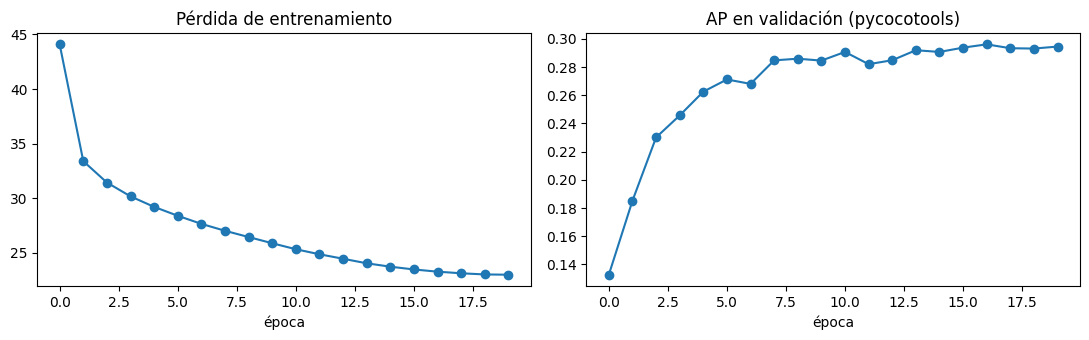

In [18]:
# Curvas de entrenamiento (history guardado en last.pt)
try:
    import matplotlib.pyplot as plt
    hist = load_ckpt(CK_LAST)["history"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot([h["loss"] for h in hist], marker="o"); ax[0].set_title("Pérdida de entrenamiento")
    ax[1].plot([h["val_ap"] for h in hist], marker="o"); ax[1].set_title("AP en validación (pycocotools)")
    for a in ax: a.set_xlabel("época")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Sin curvas:", type(e).__name__, e)

## 3. Predicciones y evaluación (`pycocotools`)

Se carga `best.pt` y se predice con la inferencia de instancias oficial (top-100), máscaras binarizadas en el tamaño real de la foto. Las predicciones se guardan en formato COCO (RLE). Misma evaluación que los demás segmentadores. Se evalúa **con clases** y también en modo **agnóstico** a partir de las mismas predicciones.

In [19]:
PRED_DIR = WORK / ("predicciones_pilot" if CFG["pilot"] else "predicciones"); PRED_DIR.mkdir(parents=True, exist_ok=True)
model = build_model().to(DEVICE)
model.load_state_dict(load_ckpt(CK_BEST)["model"]); model.eval()

EVAL, PRED_FILES = {}, {}
for s in ("val", "test"):
    t0 = time.time()
    infos, dets = predict_dets(model, s, limit=FINAL_LIMIT)
    ids = [im["id"] for im in infos]
    PRED_FILES[s] = str(fu.save_predictions(dets, PRED_DIR / f"{RUN_NAME}_{s}.json"))
    if CFG["agnostic"]:
        EVAL[s] = {"agnostic": fu.evaluate_segm(prep.coco(s, agnostic=True), dets, agnostic=True, img_ids=ids, n_folds=CFG["eval_folds"])}
    else:
        EVAL[s] = fu.evaluate_all(prep.coco(s), dets, img_ids=ids, per_class=(s == "test"), n_folds=CFG["eval_folds"])
    print(f"[{s}] {len(ids)} imágenes, {len(dets):,} detecciones, {time.time()-t0:.0f} s")

import pandas as pd
rows = []
for s, d in EVAL.items():
    for k, m in d.items():
        rows.append(dict(split=s, modo=k, AP=m["AP"], AP50=m["AP50"], AP75=m["AP75"], APs=m["APs"], APm=m["APm"], APl=m["APl"],
                         AR100=m["AR100"], AP_folds=f"{m.get('AP_fold_mean', float('nan')):.3f}±{m.get('AP_fold_std', float('nan')):.3f}"))
print(pd.DataFrame(rows).round(3).to_string(index=False))

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                          
-----------------------------------------------------------------------------------------------------------------------------------+------------+------------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED |                                                                                          
model.pixel_level_module.encoder.swin.layernorm.weight                                                                             | MISSING    |                                 

[val] 946 imágenes, 77,033 detecciones, 146 s
[test] 3911 imágenes, 315,915 detecciones, 762 s
split        modo    AP  AP50  AP75   APs   APm   APl  AR100    AP_folds
  val class_aware 0.296 0.394 0.318 0.000 0.101 0.321  0.609 0.417±0.023
  val    agnostic 0.458 0.668 0.494 0.000 0.103 0.503  0.695 0.461±0.027
 test class_aware 0.265 0.352 0.288 0.092 0.127 0.279  0.605 0.336±0.013
 test    agnostic 0.454 0.657 0.500 0.067 0.174 0.483  0.709 0.455±0.015


## 4. Eficiencia

Latencia de **extremo a extremo**: lectura, letterbox, inferencia y posproceso (siempre se calculan los 100 candidatos y sus máscaras a resolución original), 1 imagen. Solo comparable con modelos medidos en la **misma GPU**. Se anota la precisión numérica usada.

In [20]:
sample_info = next(im for im in prep.images("val") if im["id"] not in BAD["val"])
fu.reset_gpu_peak()
LAT = fu.measure_latency(lambda: infer_one(model, sample_info), warmup=5, iters=30)
EFF = dict(params=fu.count_params(model), latency=LAT, gpu_mem_mb=fu.gpu_memory_mb(), gpu=GPU, imgsz=CFG["imgsz"], precision=AMP)
print(f"Parámetros: {EFF['params']/1e6:.1f} M | latencia: {LAT['mean_ms']:.1f} ± {LAT['std_ms']:.1f} ms (p95 {LAT['p95_ms']:.1f}) en {GPU} [{AMP}]")

Parámetros: 47.5 M | latencia: 74.2 ± 0.4 ms (p95 74.9) en NVIDIA L4 [bf16]


## 5. Guardar resultados

In [21]:
OUT_RES = WORK / ("resultados_pilot" if CFG["pilot"] else "resultados")
res_path = fu.write_result(
    RUN_NAME, model=MODEL_LABEL, metrics=EVAL, prep=prep, cfg=CFG, seed=CFG["seed"], efficiency=EFF,
    train=dict(pretrained="COCO (" + HF_NAMES[CFG["model_size"]] + ")", epochs_run=INFO.get("epochs_run"), epochs_max=CFG["epochs"],
               best_epoch=INFO.get("best_epoch"), best_val_ap=INFO.get("best_val_ap"), time_s=INFO.get("time_s"),
               batch=CFG["batch"], lr=CFG["lr"], amp=AMP, pilot=CFG["pilot"]),
    files=dict(weights=str(CK_BEST), pred_val=PRED_FILES["val"], pred_test=PRED_FILES["test"]),
    notes="Segmentador agnostico (una clase 'food')." if CFG["agnostic"] else "Segmentador con 323 clases.",
    out_dir=OUT_RES)
print("Resultado guardado en:", res_path)
if CFG["pilot"]:
    print("\n✅ PILOTO COMPLETO: el flujo funciona de extremo a extremo. Pon CFG['pilot']=False y vuelve a ejecutar todo el cuadernillo.")

Resultado guardado en: /content/drive/MyDrive/calorie_counter/resultados/B4_mask2former_swin_tiny.json


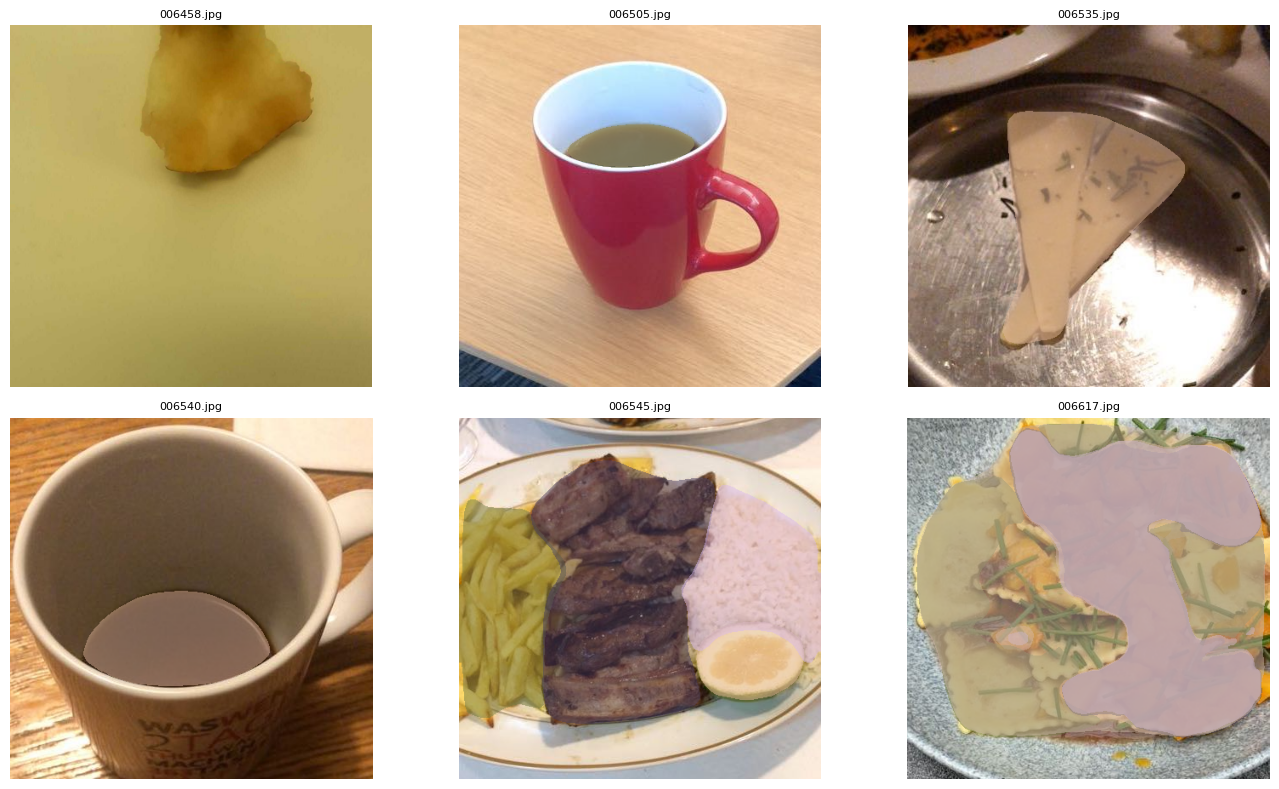

In [22]:
# Revisión cualitativa: 6 imágenes de test (puntuación >= 0.3)
try:
    import matplotlib.pyplot as plt
    rng = np.random.default_rng(0); palette = rng.integers(60, 255, (128, 3))
    tests = [im for im in prep.images("test") if im["id"] not in BAD["test"]][:6]
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for ax, im in zip(axes.flat, tests):
        img, *_ = fu.load_image_oriented(prep.image_path(im), im); arr = np.array(img).astype(float)
        sc, lb, mk = infer_one(model, im)
        for j, (m, s_) in enumerate(zip(mk.cpu().numpy(), sc.float().cpu().numpy())):
            if s_ >= 0.3: arr[m] = 0.5 * arr[m] + 0.5 * palette[j % 128]
        ax.imshow(arr.astype(np.uint8)); ax.axis("off"); ax.set_title(im["file_name"], fontsize=8)
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Sin vista cualitativa:", type(e).__name__, e)

### Siguientes pasos
- Si el piloto salió bien: `CFG["pilot"] = False` y **Ejecutar todo**. Si Colab se desconecta, vuelve a ejecutar: se reanuda desde `last.pt`.
- Comparar con **A4** (mismo tamaño): la diferencia en AP agnóstico mide el efecto de aprender las clases dentro del segmentador.
- Resultados en `{WORK}/resultados/B4_mask2former_*.json`; predicciones COCO en `{WORK}/predicciones/`.